# Ensemble of the five-fold models

Notebooks 18–21 combined the members with simple rules and judged them on fold 0 and on the public leaderboard. Now all four main families have five-fold versions (notebooks `cv/01`, `cv/03`, `cv/04`, `cv/05`). Each gives out-of-fold (OOF) probabilities for all 12,260 training images, predicted by models that did not train on them, and a test prediction that is the mean of its five fold models. This notebook combines them in the same way as notebook 19: a short list of candidates, each defined by a simple rule, compared cell by cell. What is new: the OOF predictions contain 139 named-pet labels on 125 photos instead of the 27 photos on fold 0, so every candidate can also be checked locally before an upload.

**No weight comes from the leaderboard.** Notebook 19's best weighting (`skill`) was built from the members' public scores, so its public result partly measures the public part of the test set and says little about the private part. Here no weight or threshold uses a public score. The public scores only judge the uploads afterwards.

**How a candidate has to win.** The scores are high. One named-pet photo changes OOF macro F1 by about 0.002, and the candidates differ by a few photos. So a higher OOF score alone is not an argument. A candidate replaces the equal mean only if three pieces of evidence agree:

1. **Paired count.** Among the named-pet OOF cells where it differs from the equal mean, it must be right more often than wrong, and a sign test says how likely that split is by chance.
2. **Paired bootstrap.** The 5–95% interval of its macro-F1 difference over resamples of the training images.
3. **Fold consistency.** The difference in each of the five folds: a real improvement should not come from one fold.

The same evidence answers the second question of this notebook: **fixed threshold 0.25 or one threshold per label?** For the single models, the per-label CSVs scored below the 0.25 CSVs on the leaderboard. We check whether that also holds for an ensemble, and why.

At the end, the test images on which the candidates disagree are shown for manual review.

By default the notebook only reads saved results. Submission CSVs and records are written only for the entries in `TO_SUBMIT` with `BUILD_SUBMISSION = True`, and an existing file is kept, not overwritten. Kaggle upload is always manual.

In [1]:
from __future__ import annotations

import json
import math
import os
import subprocess
import sys
from pathlib import Path

import numpy as np

BUILD_SUBMISSION = True  # Writes the CSVs listed in TO_SUBMIT and one record each; existing files are kept.
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.
CV_OUTPUT = os.environ.get('STAGE2_CV_OUTPUT')  # Same folder the model notebooks wrote to.

# CV folder -> name. All four must have a cv.json from their notebook.
MODELS = {
    'convnext': 'Exp1 ConvNeXt',
    'efficientnetv2s': 'Exp3 EfficientNetV2-S',
    'bit_r50x1': 'Exp5 BiT',
    'hrnet_w32': 'Exp7 HRNet',
}
THRESHOLD = 0.25
# Candidates: (rule, weights). Each comes from a simple rule, not from a search; see the next markdown cell.
CANDIDATES = {
    'eq4': ('mean', {'convnext': 1, 'efficientnetv2s': 1, 'bit_r50x1': 1, 'hrnet_w32': 1}),
    'hrnet_double': ('mean', {'convnext': 1, 'efficientnetv2s': 1, 'bit_r50x1': 1, 'hrnet_w32': 2}),
    'convnext_hrnet': ('mean', {'convnext': 1, 'efficientnetv2s': 0, 'bit_r50x1': 0, 'hrnet_w32': 1}),
    'logit_eq4': ('logit', {'convnext': 1, 'efficientnetv2s': 1, 'bit_r50x1': 1, 'hrnet_w32': 1}),
    'vote2': ('vote', {'convnext': 1, 'efficientnetv2s': 1, 'bit_r50x1': 1, 'hrnet_w32': 1}),
}
REFERENCE = 'eq4'
# Earlier submissions to compare with, cell by cell.
EARLIER = {
    'nb20': 'submissions/cv_ensemble_exp1_cvexp3_cvexp5_exp7_mean_025.csv',
    'nb21': 'submissions/cv_ensemble_cvexp1_cvexp3_cvexp5_exp7_mean_025.csv',
}
# Public leaderboard scores, entered by hand after each upload (Kaggle shows them on the submissions page).
PUBLIC = {
    'nb20': 0.98367, 'nb21': 0.98374,
    'eq4 025': 0.97989, 'eq4 perlabel': 0.98028, 'hrnet_double 025': 0.97854, 'vote2 025': 0.97743,
}
CELL_VALUE = 0.0007  # Public macro F1 of one named-pet cell (notebook 19).
# (candidate, '025' or 'perlabel') pairs to write as CSVs. Chosen after reading the evidence below:
# each one differs from eq4 at 0.25 in a single factor, so each upload answers one question.
TO_SUBMIT = (('eq4', '025'), ('vote2', '025'), ('hrnet_double', '025'), ('eq4', 'perlabel'))
BOOTSTRAPS = 2000
MAX_IMAGES = 24  # Test images shown in the review grid; the table below it lists all of them.

start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'cv.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory, or set STAGE2_ROOT.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CV_ROOT = Path(CV_OUTPUT) if CV_OUTPUT else ROOT / 'experiments' / 'cv'
print('CV results folder:', CV_ROOT)

CV results folder: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/cv


## The candidates and why each one is on the list

Every candidate tests one idea, with weights that follow from a stated rule. One caution: while the list was being made, the OOF scores of several ideas were looked at (votes, a double and a triple HRNet weight, all with a fixed threshold) and the list kept the ones that looked sensible. So the OOF numbers below are somewhat optimistic for the candidates, and later sections show how large that effect was:

| Candidate | Idea | Rule |
|---|---|---|
| `eq4` | reference | Equal mean of the four members at 0.25: the method of notebooks 18, 20 and 21. |
| `hrnet_double` | weight by local skill | HRNet's OOF macro F1 (0.986) is ahead of every other member by more than 0.01, five times the value of one photo; it is the only member with a lead beyond noise, so it counts double. The others are within 0.01 of each other and keep weight 1. |
| `convnext_hrnet` | fewer, better members | Keep only the two members with the best OOF scores. Tests whether the two weaker members add errors rather than fix them. |
| `logit_eq4` | another way to average | Equal weights, but average the log-odds instead of the probabilities. One very confident member is then not diluted by three unsure ones. |
| `vote2` | majority instead of average | A label is positive when at least two of the four members give it 0.25 or more. One member alone can neither add nor remove a call. |

Five candidates, two thresholding variants each: ten comparisons against one reference. With this few, a candidate that wins on all three tests is unlikely to win by chance. A longer list, or a grid of weights, would make a lucky winner likely (notebook 19 counted 1,265 different decision sets on its grid).

## Load the members

For every model we read `cv.json`, `oof.csv` and `test_mean.csv`. Each file's hash is checked against the record. All members must use the same fold file and label order, and every training image must have the same held-out fold in all of them. No model is run.

In [2]:
from stage2.cv import read_cv_summary, sha256, write_json_once, write_matrix
from stage2.ensemble import weighted_mean_probabilities
from stage2.experiment import LABEL_COLUMNS, form_submission_per_label, read_csv, score_probabilities, write_submission
from stage2.thresholds import nested_thresholds, per_label_f1

DATA_DIR = ROOT / 'data'
train_rows = read_csv(DATA_DIR / 'train.csv', ('image_id', *LABEL_COLUMNS))
train_ids = [row['image_id'] for row in train_rows]
targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in train_rows])
test_ids = [row['image_id'] for row in read_csv(DATA_DIR / 'test.csv', ('image_id',))]
fold_sha256 = sha256(ROOT / 'folds.csv')

members = {}
for key in MODELS:
    loaded = read_cv_summary(CV_ROOT / key, train_ids, test_ids)
    if loaded['record']['data']['fold_sha256'] != fold_sha256 or loaded['record']['data']['label_columns'] != list(LABEL_COLUMNS):
        raise ValueError(f'{key} used another fold file or label order.')
    members[key] = loaded
folds = next(iter(members.values()))['folds']
if any(not np.array_equal(member['folds'], folds) for member in members.values()):
    raise ValueError('The members disagree on the held-out fold of some images.')
names = list(members)
oof = {key: member['oof'] for key, member in members.items()}
test = {key: member['test'] for key, member in members.items()}
for title, (rule, weights) in CANDIDATES.items():
    if set(weights) != set(names) or rule not in ('mean', 'logit', 'vote'):
        raise ValueError(f'{title}: needs a weight for each member and a known rule.')
named = [LABEL_COLUMNS.index(label) for label in ('Moris', 'Motya', 'Biatrix')]
print('Members:', [MODELS[key] for key in names])
print(f'{len(train_ids):,} OOF images, of them {int(targets[:, named].any(axis=1).sum())} with a named pet; {len(test_ids):,} test images')

Members: ['Exp1 ConvNeXt', 'Exp3 EfficientNetV2-S', 'Exp5 BiT', 'Exp7 HRNet']
12,260 OOF images, of them 125 with a named pet; 18,673 test images


## The members alone

Pooled OOF macro F1 at 0.25, the fair per-label-threshold score (thresholds tuned on four folds and applied to the fifth), and macro AP, which needs no threshold. The last columns count the OOF mistakes on named-pet cells at 0.25.

In [3]:
errors = {}
print(f"{'model':<24}{'F1 @0.25':>10}{'F1 per-label (fair)':>21}{'AP':>9}{'pets missed':>13}{'pet false alarms':>18}")
for key in names:
    scores = score_probabilities(targets, oof[key], THRESHOLD)
    decided = oof[key] >= THRESHOLD
    errors[key] = decided[:, named] != targets[:, named].astype(bool)
    missed = int((~decided[:, named] & (targets[:, named] == 1)).sum())
    alarms = int((decided[:, named] & (targets[:, named] == 0)).sum())
    fair = members[key]['record']['per_label_thresholds']['fair_macro_f1']
    print(f"{MODELS[key]:<24}{scores['macro_f1']:>10.5f}{fair:>21.5f}{scores['macro_ap']:>9.5f}{missed:>13}{alarms:>18}")

model                     F1 @0.25  F1 per-label (fair)       AP  pets missed  pet false alarms
Exp1 ConvNeXt              0.97416              0.97187  0.99485            4                 8
Exp3 EfficientNetV2-S      0.96448              0.96522  0.98908            6                11
Exp5 BiT                   0.96656              0.96496  0.98794           10                 4
Exp7 HRNet                 0.98613              0.98262  0.99283            3                 2


## Do the members make different mistakes?

An average can only fix a mistake that most members do not share. For every pair of models we count the named-pet OOF cells that both get wrong at 0.25 (the diagonal is a model's own count). The last line counts the cells that every member gets wrong; no combination can fix those.

In [4]:
print(f"{'shared errors':<24}" + ''.join(f'{MODELS[key].split()[0]:>8}' for key in names))
for a in names:
    print(f'{MODELS[a]:<24}' + ''.join(f'{int((errors[a] & errors[b]).sum()):>8}' for b in names))
every = np.logical_and.reduce([errors[key] for key in names])
print(f'\nNamed-pet cells wrong in every member: {int(every.sum())}; wrong in at least one: {int(np.logical_or.reduce([errors[key] for key in names]).sum())}')

shared errors               Exp1    Exp3    Exp5    Exp7
Exp1 ConvNeXt                 12       2       4       2
Exp3 EfficientNetV2-S          2      17       2       4
Exp5 BiT                       4       2      14       2
Exp7 HRNet                     2       4       2       5

Named-pet cells wrong in every member: 1; wrong in at least one: 36


## The candidates on the OOF predictions

Every candidate is applied to the OOF probabilities. The fixed variant uses 0.25 (for `vote2`: at least two members at 0.25). The per-label variant tunes one threshold per label on four folds and applies it to the fifth, so its score is fair. For `vote2` the "probability" is the share of members that vote for the label, so a tuned threshold chooses how many votes each label needs.

The paired columns compare each candidate with `eq4` at 0.25 on the named-pet cells where they disagree: `fixed` counts the cells the candidate gets right and `eq4` wrong, `broken` the reverse. The sign test gives the probability of a split at least this one-sided if both were equally good. A difference that rests on two or three cells is not evidence.

In [5]:
def logit(probabilities: np.ndarray) -> np.ndarray:
    clipped = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped))


def combine(probabilities: dict, title: str) -> np.ndarray:
    rule, weights = CANDIDATES[title]
    active = [key for key in names if weights[key] > 0]
    w = np.asarray([weights[key] for key in active], float)
    if rule == 'vote':
        return np.tensordot(w / w.sum(), np.stack([probabilities[key] >= THRESHOLD for key in active]).astype(float), axes=1)
    if rule == 'logit':
        return 1 / (1 + np.exp(-np.tensordot(w / w.sum(), np.stack([logit(probabilities[key]) for key in active]), axes=1)))
    return weighted_mean_probabilities([probabilities[key] for key in active], w)


def fixed_threshold(title: str) -> float:
    return 0.5 if CANDIDATES[title][0] == 'vote' else THRESHOLD  # vote2: half of the four votes


def fair_decisions(probabilities: np.ndarray) -> tuple[np.ndarray, dict]:
    tuning = nested_thresholds(targets, probabilities, folds)
    decided = np.zeros(targets.shape, dtype=bool)
    for fold, thresholds in tuning['thresholds_by_held_out_fold'].items():
        decided[folds == fold] = probabilities[folds == fold] >= np.asarray([thresholds[label] for label in LABEL_COLUMNS])
    return decided, tuning


def macro_f1(decided: np.ndarray, rows=slice(None)) -> float:
    return float(per_label_f1(targets[rows], decided[rows].astype(float), 0.5).mean())


def sign_test(wins: int, losses: int) -> float:
    n = wins + losses
    if n == 0:
        return 1.0
    tail = sum(math.comb(n, k) for k in range(max(wins, losses), n + 1)) / 2 ** n
    return min(1.0, 2 * tail)


oof_scores, oof_decided, tunings = {}, {}, {}
for title in CANDIDATES:
    oof_scores[title] = combine(oof, title)
    oof_decided[(title, '025')] = oof_scores[title] >= fixed_threshold(title)
    oof_decided[(title, 'perlabel')], tunings[title] = fair_decisions(oof_scores[title])

truth = targets.astype(bool)
reference = oof_decided[(REFERENCE, '025')]
print(f"{'candidate':<16}{'variant':<10}{'F1':>9}{'AP':>9}{'missed':>8}{'false':>7}{'fixed':>7}{'broken':>8}{'sign p':>8}")
for (title, variant), decided in oof_decided.items():
    ap = score_probabilities(targets, oof_scores[title], THRESHOLD)['macro_ap'] if CANDIDATES[title][0] != 'vote' else float('nan')
    pets, real = decided[:, named], truth[:, named]
    differs = pets != reference[:, named]
    fixed, broken = int((differs & (pets == real)).sum()), int((differs & (pets != real)).sum())
    print(f"{title:<16}{variant:<10}{macro_f1(decided):>9.5f}{ap:>9.5f}{int((~pets & real).sum()):>8}{int((pets & ~real).sum()):>7}"
          f"{fixed:>7}{broken:>8}{sign_test(fixed, broken):>8.3f}")

candidate       variant          F1       AP  missed  false  fixed  broken  sign p
eq4             025         0.98552  0.99804       1      5      0       0   1.000
eq4             perlabel    0.99032  0.99804       2      2      3       1   0.625
hrnet_double    025         0.98728  0.99836       1      4      1       0   1.000
hrnet_double    perlabel    0.98831  0.99836       3      2      3       2   1.000
convnext_hrnet  025         0.98542  0.99885       2      4      2       2   1.000
convnext_hrnet  perlabel    0.98039  0.99885       3      6      2       5   0.453
logit_eq4       025         0.98183  0.99834       5      3      2       4   0.688
logit_eq4       perlabel    0.98562  0.99834       3      3      3       3   1.000
vote2           025         0.99022      nan       1      3      2       0   0.500
vote2           perlabel    0.98534      nan       4      2      3       3   1.000


## Bootstrap and folds: is a difference larger than the noise?

For every variant, the macro-F1 difference from `eq4` at 0.25. The bootstrap resamples the 12,260 training images 2,000 times (Poisson weights, so the same resample is used for every variant), and the interval is the 5th to 95th percentile. `P(>0)` is the share of resamples in which the variant is better. The five fold columns are the differences within each held-out fold. An interval that contains zero, or folds that disagree in sign, mean the OOF predictions cannot separate the two.

In [6]:
generator = np.random.default_rng(0)
resample_weights = generator.poisson(1.0, size=(BOOTSTRAPS, len(targets))).astype(float)


def bootstrap_macro_f1(decided: np.ndarray) -> np.ndarray:
    true_positive = resample_weights @ (decided & truth).astype(float)
    predicted = resample_weights @ decided.astype(float)
    positive = resample_weights @ truth.astype(float)
    denominator = predicted + positive
    return np.where(denominator > 0, 2 * true_positive / np.maximum(denominator, 1e-12), 0.0).mean(axis=1)


reference_boot = bootstrap_macro_f1(reference)
evidence = {}
print(f"{'candidate':<16}{'variant':<10}{'dF1':>9}  {'[5%, 95%]':<19}{'P(>0)':>7}  " + ''.join(f'{f"fold {fold}":>9}' for fold in range(5)))
for (title, variant), decided in oof_decided.items():
    difference = bootstrap_macro_f1(decided) - reference_boot
    by_fold = [macro_f1(decided, folds == fold) - macro_f1(reference, folds == fold) for fold in range(5)]
    evidence[(title, variant)] = {'delta': macro_f1(decided) - macro_f1(reference), 'low': float(np.percentile(difference, 5)),
                                  'high': float(np.percentile(difference, 95)), 'p_better': float((difference > 0).mean()), 'by_fold': by_fold}
    e = evidence[(title, variant)]
    print(f"{title:<16}{variant:<10}{e['delta']:>+9.5f}  [{e['low']:+.4f}, {e['high']:+.4f}]  {e['p_better']:>6.2f}  " + ''.join(f'{value:>+9.4f}' for value in by_fold))

candidate       variant         dF1  [5%, 95%]            P(>0)     fold 0   fold 1   fold 2   fold 3   fold 4
eq4             025        +0.00000  [+0.0000, +0.0000]    0.00    +0.0000  +0.0000  +0.0000  +0.0000  +0.0000
eq4             perlabel   +0.00479  [-0.0022, +0.0122]    0.87    +0.0006  -0.0106  +0.0112  +0.0009  +0.0207
hrnet_double    025        +0.00176  [-0.0001, +0.0052]    0.83    +0.0001  +0.0001  -0.0001  -0.0000  +0.0087
hrnet_double    perlabel   +0.00278  [-0.0052, +0.0106]    0.73    +0.0006  -0.0110  +0.0110  +0.0004  +0.0104
convnext_hrnet  025        -0.00010  [-0.0071, +0.0069]    0.50    -0.0122  +0.0003  +0.0106  -0.0000  -0.0010
convnext_hrnet  perlabel   -0.00513  [-0.0144, +0.0035]    0.18    -0.0112  -0.0195  +0.0040  +0.0009  -0.0001
logit_eq4       025        -0.00369  [-0.0123, +0.0047]    0.25    +0.0005  -0.0204  -0.0120  +0.0008  +0.0100


logit_eq4       perlabel   +0.00009  [-0.0097, +0.0092]    0.53    -0.0111  -0.0106  -0.0017  +0.0009  +0.0208
vote2           025        +0.00469  [+0.0007, +0.0101]    1.00    +0.0006  +0.0007  +0.0114  +0.0004  +0.0095
vote2           perlabel   -0.00018  [-0.0096, +0.0094]    0.51    +0.0007  -0.0109  -0.0058  +0.0009  +0.0100


## Fixed threshold or one threshold per label?

The single models' per-label CSVs scored below their 0.25 CSVs on the leaderboard. Two things can cause that, and they are checked separately.

1. **The thresholds do not help even on unseen training images.** The fair per-label score of a single model can already be below its 0.25 score (see the members table). Then per-label thresholds are fitted noise, and the leaderboard only confirms it.
2. **The thresholds do not transfer from OOF to test.** Every OOF probability comes from one model, but every test probability is the mean of five fold models. A mean of five is less extreme: where the fold models disagree, it lands between 0 and 1, where the OOF probabilities are rare. A threshold that sits in an empty region of the OOF distribution (any value between 0.1 and 0.9 gives the same OOF score) can then decide many test cells. We measure this as the share of named-pet probabilities between 0.05 and 0.95, and count the test cells a per-label threshold changes compared with 0.25.

The thresholds chosen on each set of four folds show how stable the choice is: a threshold that jumps between folds is not a property of the model.

In [7]:
def uncertain_share(probabilities: np.ndarray) -> float:
    pets = probabilities[:, named]
    return float(((pets > 0.05) & (pets < 0.95)).mean())


print(f"{'':<16}{'uncertain pet probabilities':>29}{'per-label vs 0.25, named-pet cells changed':>44}")
print(f"{'':<16}{'OOF':>14}{'test':>15}{'OOF (per 10k images)':>24}{'test (per 10k images)':>22}")
test_scores = {title: combine(test, title) for title in CANDIDATES}
for title in [*names, *CANDIDATES]:
    if title in names:
        oof_p, test_p = oof[title], test[title]
        thresholds = np.asarray([members[title]['record']['per_label_thresholds']['thresholds'][label] for label in LABEL_COLUMNS])
        fixed = THRESHOLD
    else:
        if CANDIDATES[title][0] == 'vote':
            continue
        oof_p, test_p = oof_scores[title], test_scores[title]
        thresholds = np.asarray([tunings[title]['thresholds'][label] for label in LABEL_COLUMNS])
        fixed = fixed_threshold(title)
    changed_oof = ((oof_p >= thresholds) != (oof_p >= fixed))[:, named].sum() / len(oof_p) * 1e4
    changed_test = ((test_p >= thresholds) != (test_p >= fixed))[:, named].sum() / len(test_p) * 1e4
    label = MODELS[title] if title in names else title
    print(f'{label:<24}{uncertain_share(oof_p):>6.4f}{uncertain_share(test_p):>15.4f}{changed_oof:>24.1f}{changed_test:>22.1f}')

print('\nPer-label thresholds of the reference, chosen on four folds (held-out fold in the row):')
print(f"{'':<10}" + ''.join(f'{label:>9}' for label in LABEL_COLUMNS))
for fold, thresholds in tunings[REFERENCE]['thresholds_by_held_out_fold'].items():
    print(f'fold {fold:<5}' + ''.join(f'{thresholds[label]:>9.3f}' for label in LABEL_COLUMNS))
print(f"{'all five':<10}" + ''.join(f"{tunings[REFERENCE]['thresholds'][label]:>9.3f}" for label in LABEL_COLUMNS))
print('\nFair per-label gain over 0.25, per label (reference):')
fair = per_label_f1(targets, oof_decided[(REFERENCE, 'perlabel')].astype(float), 0.5)
fixed_f1 = per_label_f1(targets, reference.astype(float), 0.5)
print('  ' + '  '.join(f'{label} {gain:+.4f}' for label, gain in zip(LABEL_COLUMNS, fair - fixed_f1)))

                  uncertain pet probabilities  per-label vs 0.25, named-pet cells changed
                           OOF           test    OOF (per 10k images) test (per 10k images)
Exp1 ConvNeXt           0.0015         0.0043                     4.9                  14.5
Exp3 EfficientNetV2-S   0.0013         0.0050                     9.0                  33.7
Exp5 BiT                0.0006         0.0042                     2.4                  16.6
Exp7 HRNet              0.0005         0.0030                     0.0                   7.0
eq4                     0.0017         0.0054                     2.4                   4.8
hrnet_double            0.0015         0.0050                     1.6                   3.2
convnext_hrnet          0.0012         0.0046                     3.3                   7.0
logit_eq4               0.0005         0.0028                     4.1                   8.6

Per-label thresholds of the reference, chosen on four folds (held-out fold in the

## The test set: which cells does each candidate change?

The labels are hidden here, so this section shows what each candidate would change, not whether the change is right. We count the test positives of every variant and the cells in which it differs from the reference and from the earlier submissions. One named-pet cell is worth about 0.0007 public macro F1 and a Cat or Dog cell about 0.00001 (notebook 19), so the named-pet columns are what matters. The matrix counts the named-pet cells in which two submissions differ.

In [8]:
variants = {}
for title in CANDIDATES:
    variants[f'{title} 025'] = test_scores[title] >= fixed_threshold(title)
    variants[f'{title} perlabel'] = test_scores[title] >= np.asarray([tunings[title]['thresholds'][label] for label in LABEL_COLUMNS])
for title, path in EARLIER.items():
    if (ROOT / path).is_file():
        rows = {row['image_id']: row for row in read_csv(ROOT / path, ('image_id', *LABEL_COLUMNS))}
        variants[title] = np.asarray([[int(rows[image_id][label]) for label in LABEL_COLUMNS] for image_id in test_ids], dtype=bool)
    else:
        print('Not found, skipped:', path)

base = variants[f'{REFERENCE} 025']
print(f"{'test positives':<22}" + ''.join(f'{label:>8}' for label in LABEL_COLUMNS) + f"{'cells vs eq4':>14}{'named':>7}")
for title, decided in variants.items():
    changed = decided != base
    print(f'{title:<22}' + ''.join(f'{int(decided[:, index].sum()):>8}' for index in range(len(LABEL_COLUMNS))) + f'{int(changed.sum()):>14}{int(changed[:, named].sum()):>7}')

short = list(variants)
print('\nNamed-pet cells in which two submissions differ:')
print(f"{'':<22}" + ''.join(f'{index:>5}' for index in range(len(short))))
for index, a in enumerate(short):
    print(f'{index:>2} {a:<19}' + ''.join(f'{int((variants[a][:, named] != variants[b][:, named]).sum()):>5}' for b in short))

test positives             Cat     Dog   Moris   Motya Biatrix  cells vs eq4  named
eq4 025                   7800    7708     174     138     184             0      0
eq4 perlabel              7776    7640     173     131     183           101      9
hrnet_double 025          7813    7707     176     136     183            29      5
hrnet_double perlabel     7769    7662     173     134     184            84      7
convnext_hrnet 025        7813    7699     175     135     183            59     11
convnext_hrnet perlabel    7764    7660     183     134     179           102     18
logit_eq4 025             7778    7682     171     132     183            58     10
logit_eq4 perlabel        7774    7629     179     137     186           117     12
vote2 025                 7817    7723     178     139     185            56     10
vote2 perlabel            7778    7681     178     139     185            61     10
nb20                      7817    7711     173     139     183            5

## Test images on which the candidates disagree

Every test image where at least two of the variants below make a different named-pet decision. The grid shows the images on which the most variants disagree. Each title lists the label in question, the variants that call it positive, and every member's probability for it. The table under the grid lists all such images, so all of them can be reviewed. The photos cannot rank the candidates, since a few images are not a sample, but they show what kind of mistake each rule risks: a pet that only one model sees, a look-alike animal, a pet too small to recognise. Set `REVIEW` to change which variants are compared. The photos are for finding patterns (what kinds of images the members disagree on). They must not be used to relabel test images or to pick a variant image by image: hand-labelling test data is not allowed in the competition and would also make every later score meaningless.

33 disputed named-pet cells in 32 test images. Variants compared: ['eq4 025', 'hrnet_double 025', 'convnext_hrnet 025', 'logit_eq4 025', 'vote2 025', 'eq4 perlabel', 'nb20', 'nb21']


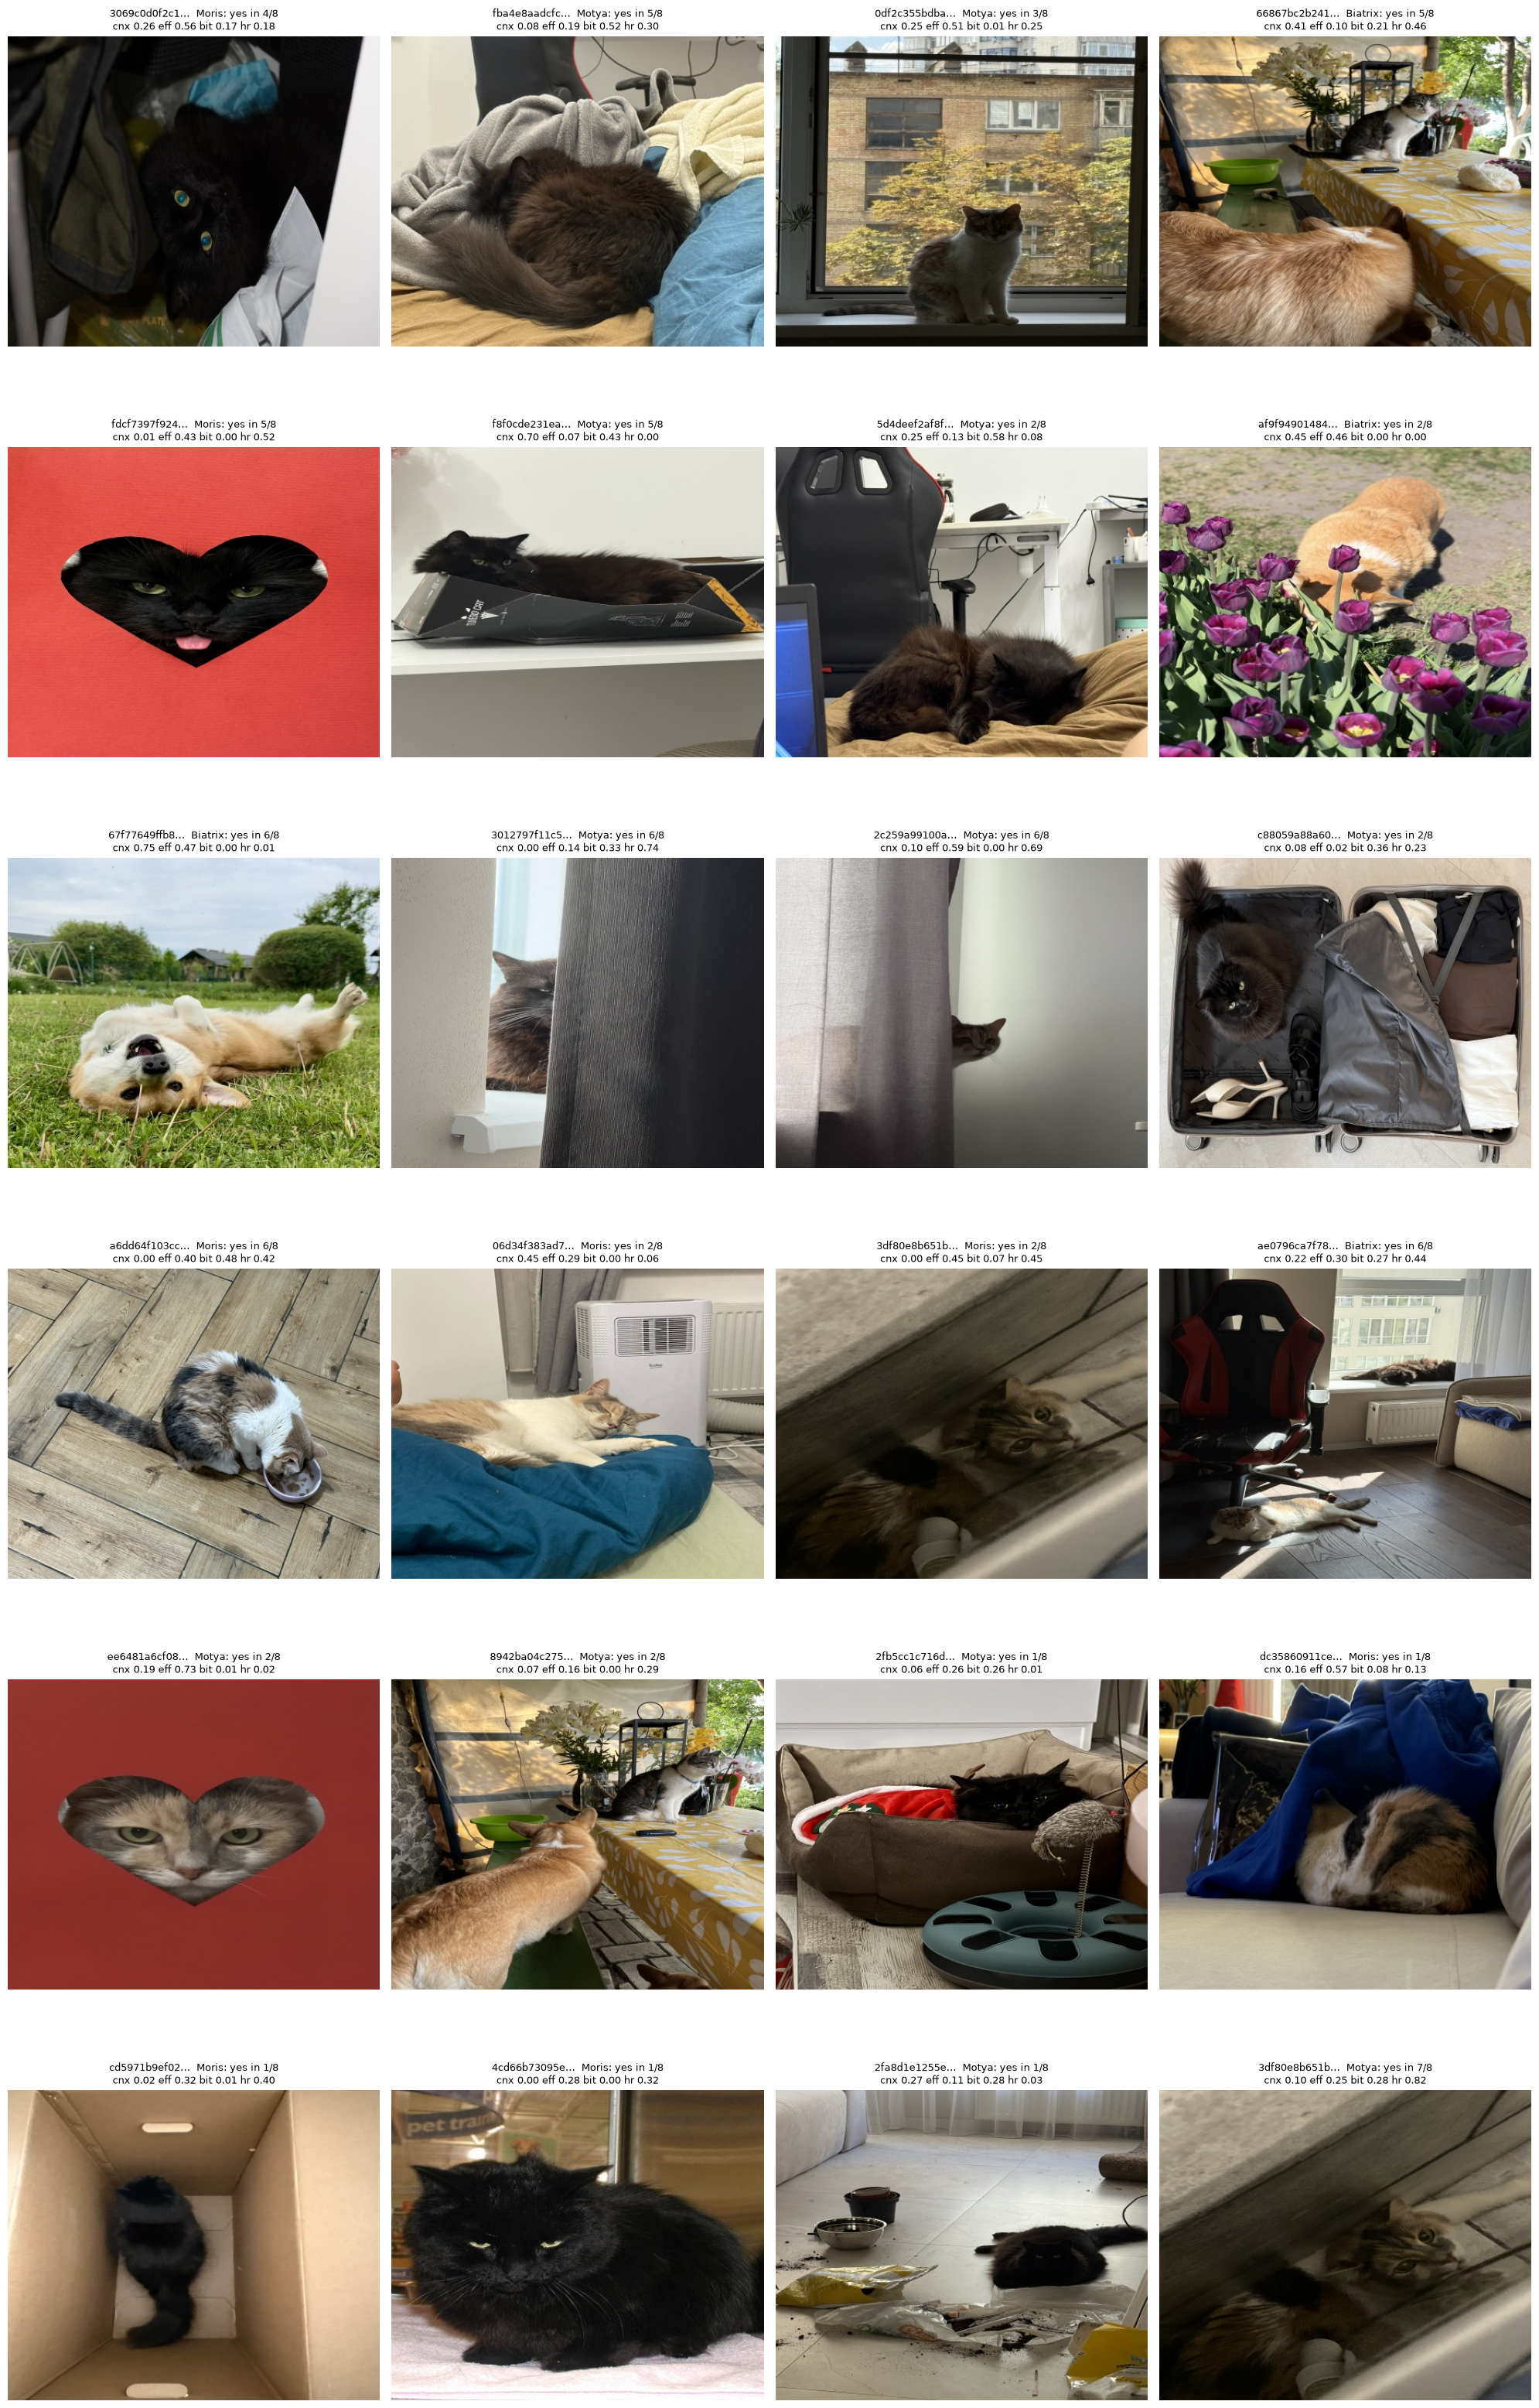


image         label            eq4 025 hrnet_double 0 convnext_hrnet  logit_eq4 025      vote2 025   eq4 perlabel           nb20           nb21   member probabilities
3069c0d0f2c1  Moris                  1              1              0              1              1              0              0              0   cnx 0.26 eff 0.56 bit 0.17 hr 0.18
fba4e8aadcfc  Motya                  1              1              0              0              1              0              1              1   cnx 0.08 eff 0.19 bit 0.52 hr 0.30
0df2c355bdba  Motya                  1              1              0              0              0              0              0              1   cnx 0.25 eff 0.51 bit 0.01 hr 0.25
66867bc2b241  Biatrix                1              1              1              1              1              0              0              0   cnx 0.41 eff 0.10 bit 0.21 hr 0.46
fdcf7397f924  Moris                  0              1              1              0              1          

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

REVIEW = [name for name in variants if name.endswith(' 025')] + [f'{REFERENCE} perlabel'] + [name for name in EARLIER if name in variants]
stacked = np.stack([variants[name][:, named] for name in REVIEW])  # (variants, images, 3 pets)
positive_votes = stacked.sum(axis=0)
disputed = (positive_votes > 0) & (positive_votes < len(REVIEW))
rows, pets = np.nonzero(disputed)
order = np.argsort(-np.minimum(positive_votes[rows, pets], len(REVIEW) - positive_votes[rows, pets]), kind='stable')
rows, pets = rows[order], pets[order]
short_names = {'convnext': 'cnx', 'efficientnetv2s': 'eff', 'bit_r50x1': 'bit', 'hrnet_w32': 'hr'}
print(f'{len(rows)} disputed named-pet cells in {len(set(rows.tolist()))} test images. Variants compared: {REVIEW}')


def describe(row: int, pet: int) -> tuple[str, str]:
    label = LABEL_COLUMNS[named[pet]]
    yes = [name for name, decided in zip(REVIEW, stacked[:, row, pet]) if decided]
    probabilities = ' '.join(f'{short_names[key]} {test[key][row, named[pet]]:.2f}' for key in names)
    return label, f'{label}: yes in {len(yes)}/{len(REVIEW)}\n{probabilities}'


shown = rows[:MAX_IMAGES], pets[:MAX_IMAGES]
columns = 4
lines = max(1, -(-len(shown[0]) // columns))
figure, axes = plt.subplots(lines, columns, figsize=(5 * columns, 5.4 * lines), squeeze=False)
for axis in axes.ravel():
    axis.axis('off')
for axis, row, pet in zip(axes.ravel(), *shown):
    with Image.open(DATA_DIR / 'test' / f'{test_ids[row]}.jpg') as photo:
        axis.imshow(photo.convert('RGB'))
    axis.set_title(f'{test_ids[row][:12]}…  ' + describe(row, pet)[1], fontsize=9)
plt.tight_layout()
plt.show()

print(f"\n{'image':<14}{'label':<9}" + ''.join(f'{name[:14]:>15}' for name in REVIEW) + '   member probabilities')
for row, pet in zip(rows, pets):
    label = LABEL_COLUMNS[named[pet]]
    print(f'{test_ids[row][:12]:<14}{label:<9}' + ''.join(f'{int(decided):>15}' for decided in stacked[:, row, pet])
          + '   ' + ' '.join(f'{short_names[key]} {test[key][row, named[pet]]:.2f}' for key in names))

## Write the submission files

One CSV per entry in `TO_SUBMIT`, in sample-submission order, with the candidate's OOF and test scores and a record under `experiments/cv/ensemble/<run-id>/`. The record holds the rule, the weights, the thresholds and the OOF evidence from above. Existing files are kept. Upload by hand and write the public score into the record and the table below.

In [10]:
git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True).stdout.strip() or None
member_tag = '_'.join(names)
if not BUILD_SUBMISSION or not TO_SUBMIT:
    print('No submission CSV built. Set TO_SUBMIT after reading the evidence above.')
for title, variant in TO_SUBMIT if BUILD_SUBMISSION else ():
    rule, weights = CANDIDATES[title]
    run_id = f'cv_ensemble_{title}_{variant}_{member_tag}'
    result_dir = CV_ROOT / 'ensemble' / run_id
    submission = ROOT / 'submissions' / f'cv_ensemble_{title}_{variant}.csv'
    if (result_dir / 'record.json').exists() or submission.exists():
        print('Kept existing', run_id)
        continue
    if variant == 'perlabel':
        thresholds = np.asarray([tunings[title]['thresholds'][label] for label in LABEL_COLUMNS])
    else:
        thresholds = np.full(len(LABEL_COLUMNS), fixed_threshold(title))
    rows = form_submission_per_label(DATA_DIR / 'sample_submission.csv', test_ids, np.clip(test_scores[title], 0, 1), thresholds)
    write_matrix(result_dir / 'oof.csv', train_ids, np.clip(oof_scores[title], 0, 1), folds)
    write_matrix(result_dir / 'test.csv', test_ids, np.clip(test_scores[title], 0, 1))
    write_submission(submission, rows)
    e = evidence[(title, variant)]
    write_json_once(result_dir / 'record.json', {
        'run_id': run_id, 'status': 'completed', 'rule': rule,
        'method': {'mean': 'weighted mean of five-fold member probabilities', 'logit': 'weighted mean of member log-odds',
                   'vote': 'share of members with probability >= 0.25'}[rule] + (', then per-label thresholds' if variant == 'perlabel' else ', then fixed threshold'),
        'members': {key: {'name': MODELS[key], 'weight': weights[key], 'cv_record_sha256': sha256(CV_ROOT / key / 'cv.json')} for key in names},
        'thresholds': dict(zip(LABEL_COLUMNS, map(float, thresholds))),
        'oof_macro_f1': macro_f1(oof_decided[(title, variant)]),
        'oof_vs_eq4_at_025': {'delta': e['delta'], 'bootstrap_5_95': [e['low'], e['high']], 'p_better': e['p_better'], 'by_fold': e['by_fold']},
        'thresholds_by_held_out_fold': {str(k): v for k, v in tunings[title]['thresholds_by_held_out_fold'].items()} if variant == 'perlabel' else None,
        'data': {'fold_file': 'folds.csv', 'fold_sha256': fold_sha256, 'label_columns': list(LABEL_COLUMNS)},
        'submission_csv': str(submission.relative_to(ROOT)), 'submission_sha256': sha256(submission),
        'positives': {label: sum(row[label] for row in rows) for label in LABEL_COLUMNS},
        'git_commit': git_commit, 'public_leaderboard_score': None,
    })
    print('Wrote', submission.relative_to(ROOT))

Kept existing cv_ensemble_eq4_025_convnext_efficientnetv2s_bit_r50x1_hrnet_w32
Kept existing cv_ensemble_vote2_025_convnext_efficientnetv2s_bit_r50x1_hrnet_w32
Kept existing cv_ensemble_hrnet_double_025_convnext_efficientnetv2s_bit_r50x1_hrnet_w32
Kept existing cv_ensemble_eq4_perlabel_convnext_efficientnetv2s_bit_r50x1_hrnet_w32


## What the leaderboard said

The four ensemble variants and notebook 21 were uploaded, and their public scores are in `PUBLIC` above. This section reads them against the OOF evidence. One named-pet cell is worth about 0.0007, so a gap of 0.0014 is two cells. The first table gives, for every pair of submissions, the number of named-pet cells in which they differ and the public gap in cells. The second compares the gain that the OOF predicted for each candidate with the gain the leaderboard gave. The third asks what the test set looks like compared with the OOF set: the share of positives for each named pet, how uncertain the members are, and how much a single fold model of each family differs from the five-fold mean on the test set.

In [11]:
from stage2.ensemble import read_probabilities

order = sorted(PUBLIC, key=PUBLIC.get, reverse=True)
print(f"{'':<18}{'public':>8}  named-pet cells differing / public gap in cells (row minus column)")
print(f"{'':<18}{'':>8}  " + ''.join(f'{title[:12]:>14}' for title in order))
for a in order:
    print(f'{a:<18}{PUBLIC[a]:>8.5f}  ' + ''.join(f'{int((variants[a][:, named] != variants[b][:, named]).sum()):>7}/{(PUBLIC[a] - PUBLIC[b]) / CELL_VALUE:>+5.1f}' for b in order))

print(f"\n{'candidate (0.25 unless noted)':<30}{'OOF gain vs eq4':>17}{'public gain vs eq4':>20}{'public minus OOF':>18}")
for title in ('hrnet_double 025', 'eq4 perlabel', 'vote2 025'):
    key = tuple(title.split())
    predicted = evidence[key]['delta']
    realised = PUBLIC[title] - PUBLIC['eq4 025']
    print(f'{title:<30}{predicted:>+17.4f}{realised:>+20.4f}{realised - predicted:>+18.4f}')
print(f"\nOOF macro F1 of eq4 at 0.25: {macro_f1(reference):.5f}; public {PUBLIC['eq4 025']:.5f}; the OOF set is {macro_f1(reference) - PUBLIC['eq4 025']:.4f} more optimistic, for a candidate that was not tuned.")

print('\nPositive rate of each label: training images vs test images (eq4 at 0.25, and the cells all four members vote for)')
unanimous_test = np.sum([test[key] >= THRESHOLD for key in names], axis=0) == len(names)
unanimous_oof = np.sum([oof[key] >= THRESHOLD for key in names], axis=0) == len(names)
for index in named:
    print(f'  {LABEL_COLUMNS[index]:<8} train {targets[:, index].mean():.4f}   test {(test_scores[REFERENCE][:, index] >= THRESHOLD).mean():.4f}   '
          f'unanimous: OOF {int(unanimous_oof[:, index].sum())} of {int(targets[:, index].sum())} true, test {int(unanimous_test[:, index].sum())}')

print('\nNamed-pet test cells in which a single fold model differs from the five-fold mean of its family (one value per fold):')
for key in names:
    fold_models = [read_probabilities(CV_ROOT / key / f'fold{fold}' / 'test.csv', test_ids) for fold in range(5)]
    mean_decided = test[key] >= THRESHOLD
    print(f'  {MODELS[key]:<24}' + ''.join(f"{int(((model >= THRESHOLD) != mean_decided)[:, named].sum()):>5}" for model in fold_models))

                    public  named-pet cells differing / public gap in cells (row minus column)
                                      nb21          nb20  eq4 perlabel       eq4 025  hrnet_double     vote2 025
nb21               0.98374        0/ +0.0      5/ +0.1     13/ +4.9     10/ +5.5     11/ +7.4     18/ +9.0
nb20               0.98367        5/ -0.1      0/ +0.0     12/ +4.8     11/ +5.4     12/ +7.3     15/ +8.9
eq4 perlabel       0.98028       13/ -4.9     12/ -4.8      0/ +0.0      9/ +0.6     10/ +2.5     17/ +4.1
eq4 025            0.97989       10/ -5.5     11/ -5.4      9/ -0.6      0/ +0.0      5/ +1.9     10/ +3.5
hrnet_double 025   0.97854       11/ -7.4     12/ -7.3     10/ -2.5      5/ -1.9      0/ +0.0     11/ +1.6
vote2 025          0.97743       18/ -9.0     15/ -8.9     17/ -4.1     10/ -3.5     11/ -1.6      0/ +0.0

candidate (0.25 unless noted)   OOF gain vs eq4  public gain vs eq4  public minus OOF
hrnet_double 025                        +0.0018             -0.

  Exp1 ConvNeXt              39   25   25   25   34


  Exp3 EfficientNetV2-S      52   65   50   37   79


  Exp5 BiT                   45   65   39   74   52


  Exp7 HRNet                 31   53   57   24   17


## One shared threshold for the ensemble

Fixed 0.25 was chosen for single models. The mean of four members is a different score, so its best threshold can differ, and the OOF curve below shows it does. A single shared threshold has one free value instead of five, so it should be far steadier than the per-label thresholds, whose Biatrix value jumped between folds. The second block repeats the curve with every named-pet photo counted twice, which is the pet rate the test set has: if doubling the pets moved the best threshold a lot, the OOF curve could not be trusted on the test set.

In [12]:
grid = np.round(np.arange(0.05, 0.80, 0.01), 2)


def macro_at(probabilities: np.ndarray, threshold: float, rows=slice(None)) -> float:
    return float(per_label_f1(targets[rows], probabilities[rows], threshold).mean())


def pet_f1_weighted(probabilities: np.ndarray, threshold: float, pet_weight: float) -> float:
    values = []
    for index in named:
        predicted, positive = probabilities[:, index] >= threshold, truth[:, index]
        tp, fp, fn = pet_weight * (predicted & positive).sum(), (predicted & ~positive).sum(), pet_weight * (~predicted & positive).sum()
        values.append(2 * tp / (2 * tp + fp + fn))
    return float(np.mean(values))


mean_scores = oof_scores[REFERENCE]
print(f"{'threshold':>9}{'macro F1':>10}{'pet F1':>9}{'pet F1, pets x2':>17}{'test named-pet positives':>28}")
for threshold in (0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50):
    positives = (test_scores[REFERENCE] >= threshold)[:, named].sum(axis=0).tolist()
    print(f'{threshold:>9.2f}{macro_at(mean_scores, threshold):>10.5f}{pet_f1_weighted(mean_scores, threshold, 1):>9.4f}{pet_f1_weighted(mean_scores, threshold, 2):>17.4f}{str(positives):>28}')

chosen_by_fold, shared_decided = [], np.zeros(targets.shape, dtype=bool)
for fold in range(5):
    fit = folds != fold
    curve = np.array([macro_at(mean_scores, threshold, fit) for threshold in grid])
    value = float(np.median(grid[np.isclose(curve, curve.max())]))
    chosen_by_fold.append(value)
    shared_decided[~fit] = mean_scores[~fit] >= value
print(f'\nShared threshold chosen on four folds, per held-out fold: {chosen_by_fold}')
print(f'Fair macro F1: {macro_f1(shared_decided):.5f} (fixed 0.25: {macro_f1(reference):.5f}; five per-label thresholds: {macro_f1(oof_decided[(REFERENCE, "perlabel")]):.5f})')
change = (test_scores[REFERENCE] >= np.median(chosen_by_fold)) != (test_scores[REFERENCE] >= THRESHOLD)
print(f'On the test set a shared threshold of {np.median(chosen_by_fold):.3f} changes {int(change[:, named].sum())} named-pet cells compared with 0.25, '
      f"and the per-label thresholds of eq4 changed {int((variants['eq4 perlabel'] != variants['eq4 025'])[:, named].sum())}.")

threshold  macro F1   pet F1  pet F1, pets x2    test named-pet positives
     0.15   0.97086   0.9580           0.9770             [187, 146, 187]
     0.20   0.97858   0.9700           0.9833             [179, 139, 185]
     0.25   0.98552   0.9797           0.9882             [174, 138, 184]
     0.30   0.99245   0.9901           0.9935             [173, 134, 182]
     0.35   0.99257   0.9901           0.9935             [169, 132, 178]
     0.40   0.98831   0.9830           0.9864             [165, 130, 177]
     0.50   0.98170   0.9717           0.9751             [156, 127, 175]



Shared threshold chosen on four folds, per held-out fold: [0.335, 0.335, 0.34, 0.33, 0.335]
Fair macro F1: 0.99257 (fixed 0.25: 0.98552; five per-label thresholds: 0.99032)
On the test set a shared threshold of 0.335 changes 12 named-pet cells compared with 0.25, and the per-label thresholds of eq4 changed 9.


## Results and conclusions

| Submission | OOF macro F1 | Public LB | vs `eq4` at 0.25, in named-pet cells |
|---|---:|---:|---:|
| Notebook 21: ConvNeXt, EfficientNet, BiT five-fold, HRNet fold-0, mean, 0.25 | n/a (HRNet fold 0 only) | **0.98374** | +5.5 |
| Notebook 20: EfficientNet, BiT five-fold, ConvNeXt and HRNet fold-0, mean, 0.25 | n/a | 0.98367 | +5.4 |
| `eq4` per-label thresholds (`cv_ensemble_eq4_perlabel.csv`) | 0.99032 (fair) | 0.98028 | +0.6 |
| **`eq4`: equal mean of the four five-fold models, 0.25** (`cv_ensemble_eq4_025.csv`) | 0.98552 | 0.97989 | 0 |
| `hrnet_double`, 0.25 | 0.98728 | 0.97854 | −1.9 |
| `vote2`, 0.25 | 0.99022 | 0.97743 | −3.5 |
| Reference: EfficientNet five-fold alone, 0.25 / per-label (notebook `cv/03`) | 0.96448 / 0.96522 (fair) | 0.97718 / 0.96176 | — |

**1. The OOF gains did not appear on the leaderboard.** `hrnet_double`, per-label thresholds and `vote2` were predicted at +0.0018, +0.0048 and +0.0047 over `eq4`; they scored −0.0014, +0.0004 and −0.0025. All three landed 0.003 to 0.007 below their prediction. Two things explain it. First, the candidates were not independent of the OOF: several ideas were looked at on the OOF set before the list was fixed, so the ones that remain look better there than they are (the usual winner's curse). Second, the OOF set is simply optimistic about the test set: `eq4` itself, which was not tuned, scores 0.0056 lower publicly (0.97989) than on OOF (0.98552).

**2. The test set is not the OOF set.** The members vote for named pets about twice as often on the test set as the training images contain them (Moris 0.0093 against 0.0046, Motya 0.0074 against 0.0034, Biatrix 0.0099 against 0.0033), and all four members agree on most of those cells, so the pets really are there. The members are also three times as often unsure on the test set (0.0054 of named-pet probabilities between 0.05 and 0.95, against 0.0017 on OOF). The disputed test images include heart-shaped crops, partly hidden pets and pets at the edge of the frame. Evidence measured on OOF therefore transfers to the test set with a loss, and a difference of one or two OOF photos (0.002 to 0.004) is smaller than that loss.

**3. Everything we uploaded lies within 0.0063, about nine cells.** The two best submissions (notebooks 20 and 21) are tied (0.1 cell apart). Both use the old fold-0 HRNet instead of the five-fold HRNet, and they are 5.5 cells above `eq4`, which differs from notebook 21 in only that member. Ten named-pet cells separate them, so notebook 21 got about eight of the ten right, and a fair coin does that at least as well 5.5% of the time. We also picked the best of the uploads, so this is not evidence that the fold-0 HRNet is better. A single fold model differs from its family's five-fold mean in 17 to 79 named-pet cells (HRNet 17 to 57), so which fold model enters the mean moves the score by several cells by chance alone.

**4. Fixed or per-label thresholds: a tie, as for the single models' mean.** Per-label thresholds changed 9 named-pet cells of `eq4` and the score moved by 0.6 cell. The OOF predicted +0.0048. The shared-threshold section shows that the OOF does prefer a higher threshold for the mean of four (0.335 in all five folds, fair macro F1 0.99257, still the best at 0.30 to 0.35 when the pets count double) but it changes only 12 test cells, and the per-label experiment, which moved the pets' thresholds into the same 0.30 to 0.37 range, shows that these cells are not worth much on the test set. For a single model the same idea lost 0.0154 (EfficientNet, 0.97718 to 0.96176).

**5. What the leaderboard cannot decide.** Rankings between the mean ensembles are separated by at most nine cells, the test set shifted from the OOF set, and every extra upload makes the best score more likely to be luck. We therefore keep the rule that no weight or threshold is chosen by public score. `eq4` at 0.25 is the reference method: equal weights, every member five-fold, one fixed threshold. Notebook 21 is its best-scoring variant and is kept as the second candidate for the final selection, which makes the two candidates a hedge (they differ in 10 cells), not a verdict.

**6. Manual review of the disputed test images.** _Notes on what kinds of photos the members disagree on (not which variant is right)._